
<h1>Machine Learning</h1>

<hr style="border:2px solid gray;">


Objective
    
Bike Sharing Demand Prediction Challenge, where the goal is to predict the number of hourly bike rentals, using weather, time, and seasonal data. 

Exploratory Data Analysis (EDA) 

Examine dataset size, missing values, and feature types.
Visualize relationships between key features and the target variable (count).
Suggest which variables are likely to be most informative.

In [1]:
import pandas as pd
import numpy as np

In [2]:
bikes_train_df = pd.read_csv("bike_train.csv")
bikes_test_df  = pd.read_csv("bike_test.csv")

In [3]:
# ============================================================
# 1. EXPLORATORY DATA ANALYSIS
# ============================================================

# for visual inspection of the data 
bikes_train_df

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2012-07-15 7:00:00,3,0,0,1,28.70000,33.335000,79,6.003200,17,30,47
1,2012-08-14 15:00:00,3,0,1,1,33.62000,37.880000,46,15.001300,84,199,283
2,2011-02-06 6:00:00,1,0,0,1,10.66000,12.880000,60,15.001300,0,1,1
3,2012-05-06 17:00:02,2,0,0,2,26.42506,30.566166,61,9.512288,198,330,531
4,2012-01-09 2:00:00,1,0,1,1,9.84000,12.120000,56,8.998100,2,3,5
...,...,...,...,...,...,...,...,...,...,...,...,...
10445,2012-10-14 13:00:00,4,0,0,1,26.24000,31.060000,41,30.002600,218,401,619
10446,2011-03-12 22:00:00,1,0,0,1,14.76000,18.940000,71,0.000000,7,56,63
10447,2011-04-07 6:00:00,2,0,1,1,13.12000,15.150000,81,16.997900,5,59,64
10448,2012-08-19 9:00:00,3,0,0,2,27.06000,31.060000,74,0.000000,86,184,270


In [4]:
# first information regarding null values data types and column names
bikes_train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10450 entries, 0 to 10449
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10450 non-null  object 
 1   season      10450 non-null  int64  
 2   holiday     10450 non-null  int64  
 3   workingday  10450 non-null  int64  
 4   weather     10450 non-null  int64  
 5   temp        10450 non-null  float64
 6   atemp       10450 non-null  float64
 7   humidity    10450 non-null  int64  
 8   windspeed   10450 non-null  float64
 9   casual      10450 non-null  int64  
 10  registered  10450 non-null  int64  
 11  count       10450 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 979.8+ KB


In [5]:
# Details on missing values 

print("\nMissing values in train:")
print(bikes_train_df.isna().sum())

print("\nMissing values in test:")
print(bikes_test_df.isna().sum())


Missing values in train:
datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64

Missing values in test:
datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
dtype: int64


In [6]:
# detailed analysis on labels 

from ydata_profiling import ProfileReport

profile = ProfileReport(bikes_train_df)
profile.to_notebook_iframe()

/tmp/ipykernel_5021/220891163.py:3: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 12/12 [00:01<00:00, 10.97it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# visualisations of different features 

# Continuous features vs count
for col in ["temp", "humidity", "windspeed"]:
    sns.scatterplot(data=bikes_train_df, x=col, y="count", alpha=0.2)
    plt.title(f"{col} vs count")
    plt.show()

In [9]:
# Season vs count
sns.boxplot(data=bikes_train_df, x="season", y="count")
plt.title("Count by season")
plt.show()

In [10]:
# Weather vs count
sns.boxplot(data=bikes_train_df, x="weather", y="count")
plt.title("Count by weather")
plt.show()

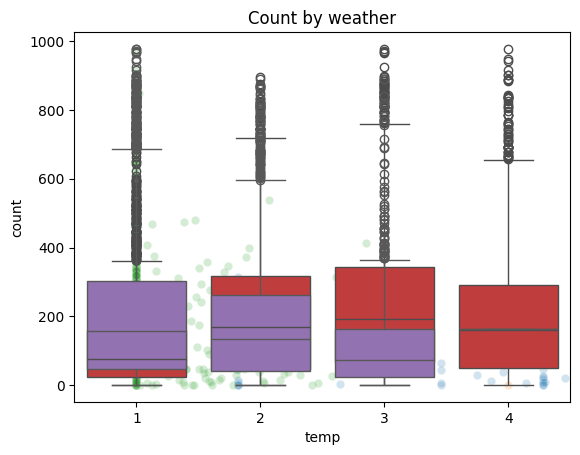

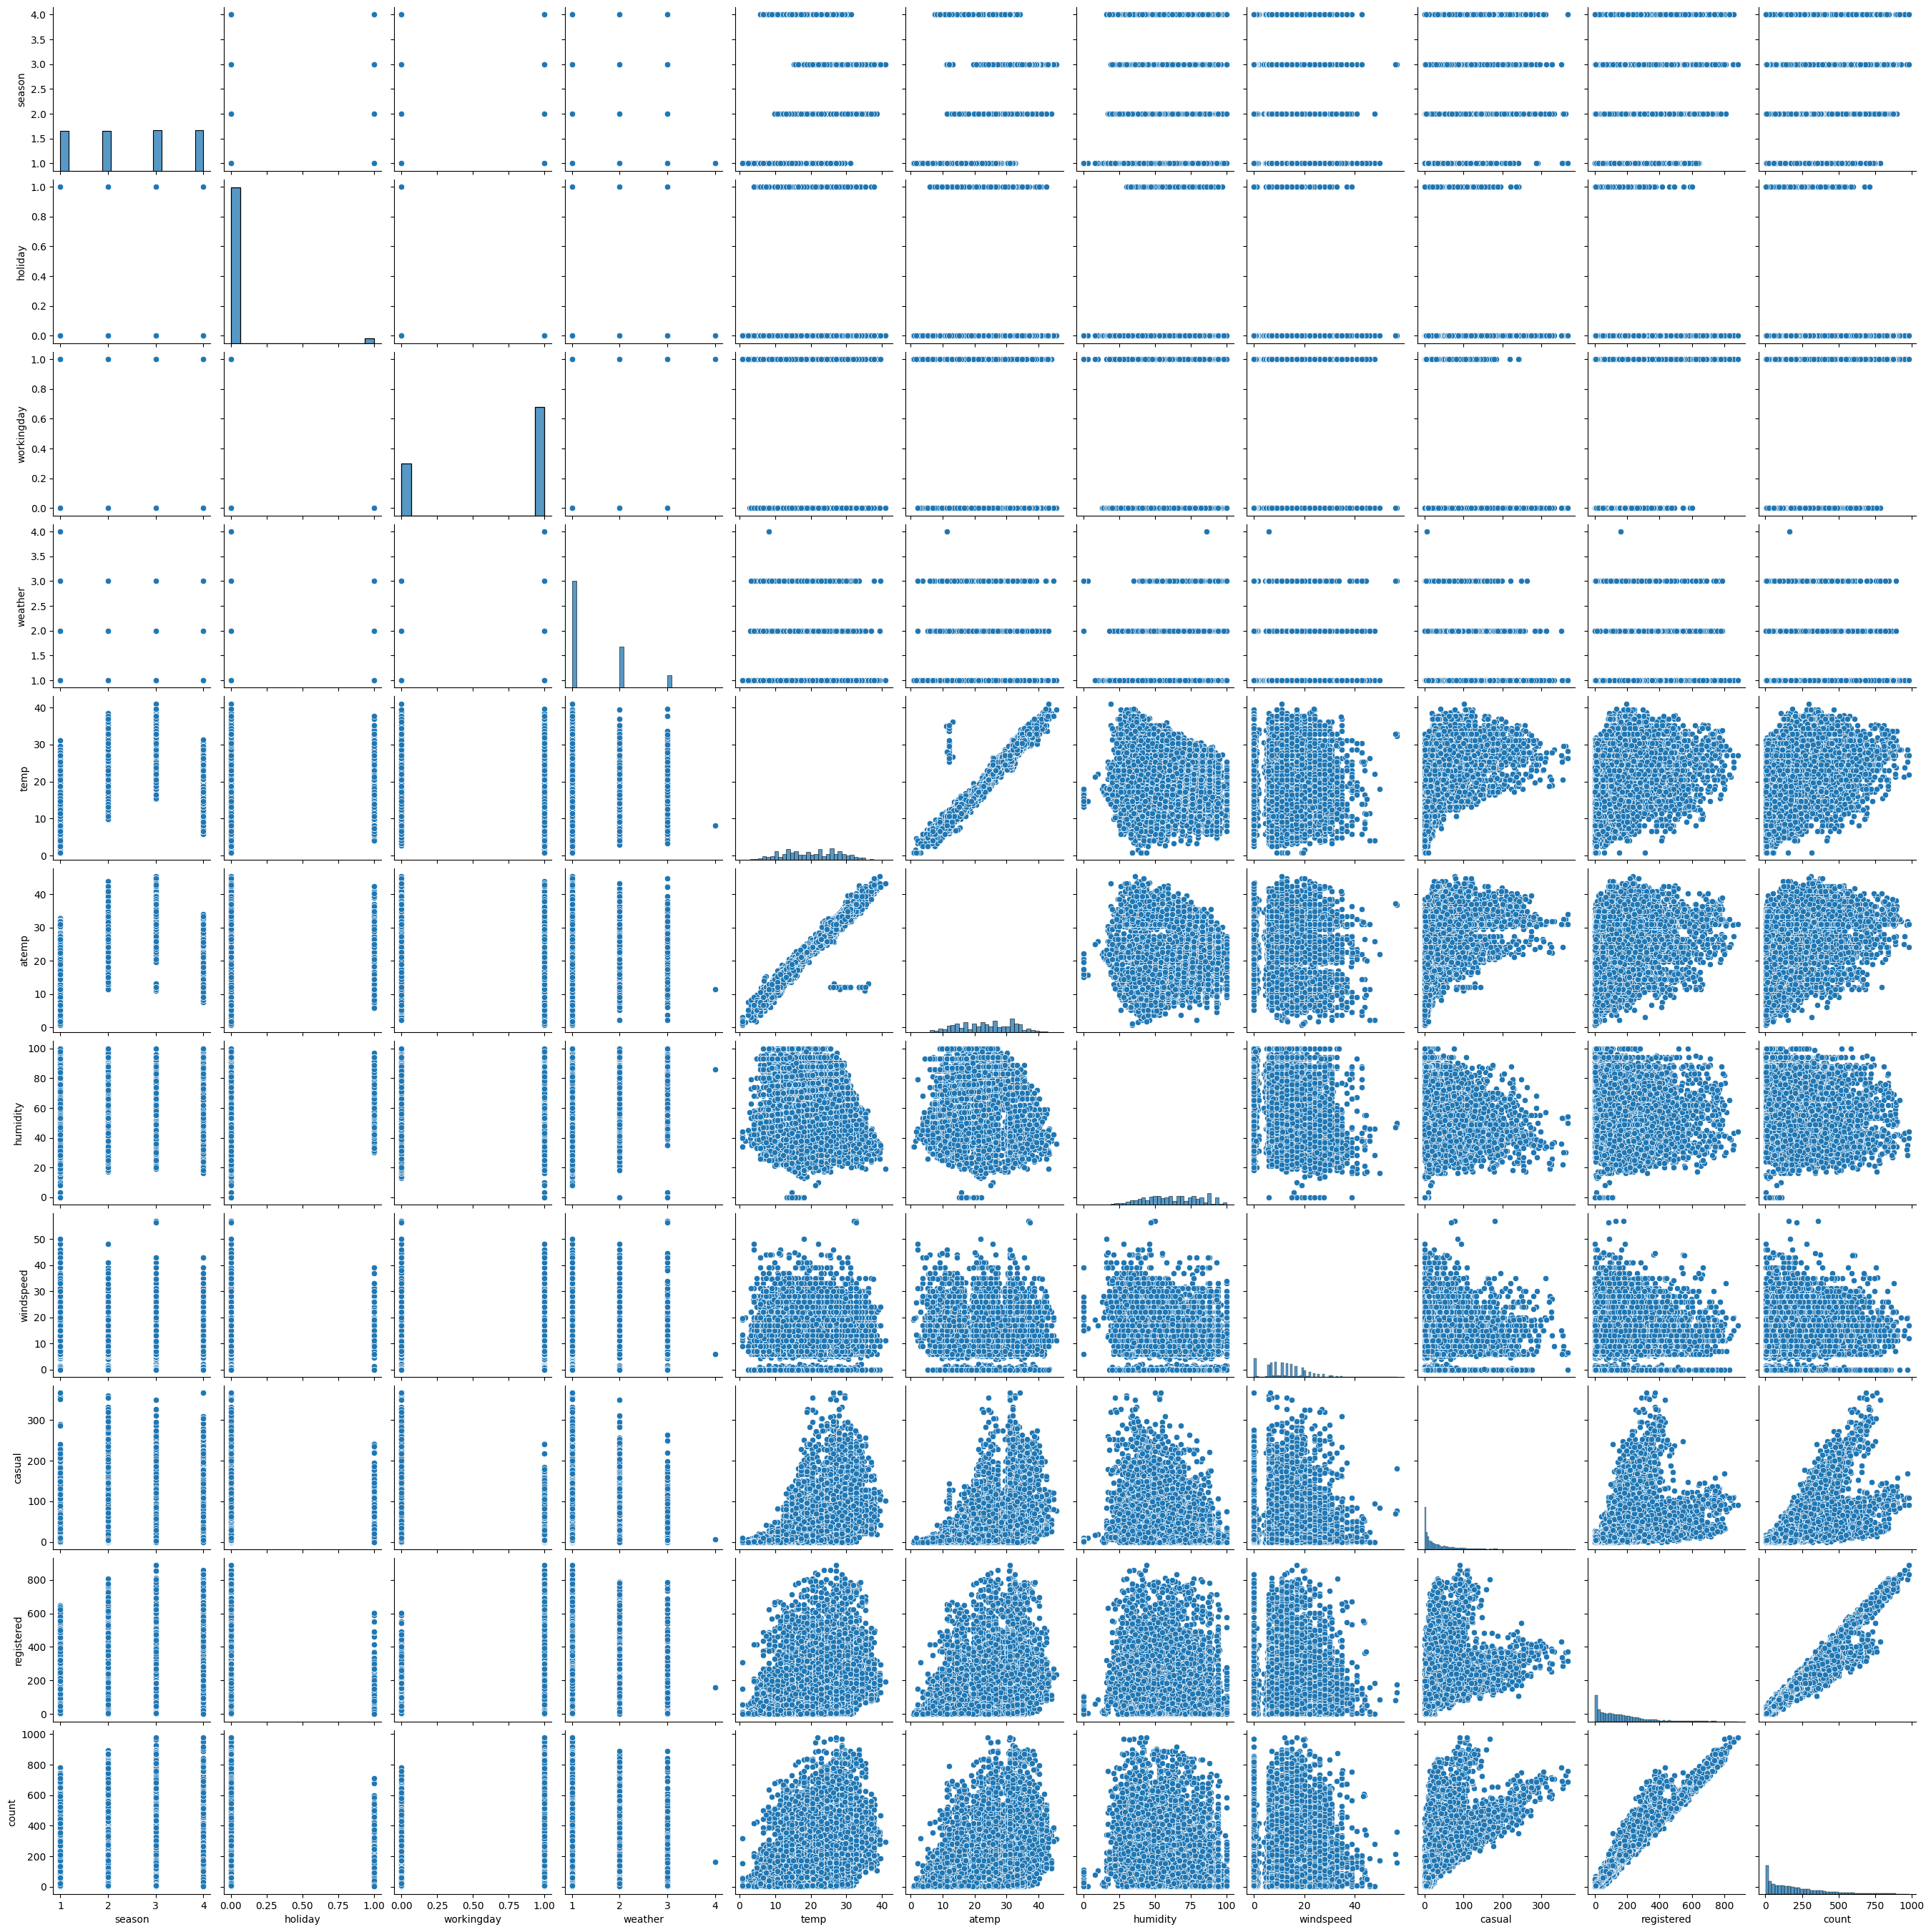

In [11]:
%matplotlib inline
sns.pairplot(bikes_train_df)
plt.show()

Feature Engineering

Derive features from datetime (hour, weekday, month, season), encode categorical variables, and transformations to capture nonlinear trends to improve your model performance. 

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [12]:
bikes_train_df['datetime'] = pd.to_datetime(bikes_train_df['datetime'], dayfirst=True)
bikes_test_df['datetime'] = pd.to_datetime(bikes_test_df['datetime'], dayfirst=True)

/tmp/ipykernel_5021/3512167994.py:1: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  bikes_train_df['datetime'] = pd.to_datetime(bikes_train_df['datetime'], dayfirst=True)


In [13]:
# ============================================================
# 2. FEATURE ENGINEERING
# ============================================================

def engineer_features(df, has_count=True):
    
    # Check which columns exist before dropping them
    columns_to_drop = []
    for col in ["count", "casual", "registered"]:
        if col in df.columns:
            columns_to_drop.append(col)
    
    # Only drop columns that actually exist in the DataFrame
    data = df.drop(columns=columns_to_drop).copy()

    # Convert datetime
    dt = pd.to_datetime(data["datetime"])

    data["year"] = dt.dt.year - 2011
    data["month"] = dt.dt.month
    data["day"] = dt.dt.day
    data["hour"] = dt.dt.hour
    data["dow"] = dt.dt.dayofweek

    # Remove original datetime
    data = data.drop(columns=["datetime"])

    # ============================================================
    # 3. TARGET

    # Check if 'count' column exists and process accordingly
    if has_count and "count" in df.columns:
        y = df["count"]
    else:
        # Return None if count column is missing or not needed
        # This allows the rest of the feature engineering to continue
        y = None

    # ============================================================
    # 4. NON-LINEAR FEATURES
    #    Still a linear model because Ridge is fitted to engineered features.

    for col in ["temp", "atemp", "humidity", "windspeed"]:
        data[col + "_sq"] = data[col] ** 2

    # ============================================================
    # 5. ONE-HOT ENCODING

    categorical_cols = [
        "season",
        "holiday",
        "workingday",
        "weather",
        "year",
        "month",
        "day",
        "hour",
        "dow"
    ]

    X = pd.get_dummies(
        data,
        columns=categorical_cols,
        drop_first=False,
        dtype=float
    )

    # ============================================================
    # 6. ADD IMPORTANT INTERACTION FEATURES

    interaction_pairs = [
        ("hour", "workingday"),
        ("hour", "season"),
        ("hour", "weather"),
        ("hour", "year"),
        ("hour", "dow"),
        ("month", "year"),
        ("month", "season"),
        ("workingday", "weather")
    ]

    for a, b in interaction_pairs:

        A = pd.get_dummies(
            data[a],
            prefix=a,
            dtype=float
        )

        B = pd.get_dummies(
            data[b],
            prefix=b,
            dtype=float
        )

        interaction = np.einsum(
            "ij,ik->ijk",
            A.values,
            B.values
        ).reshape(len(data), -1)

        names = [
            f"{x}_{z}"
            for x in A.columns
            for z in B.columns
        ]

        interaction_df = pd.DataFrame(
            interaction,
            index=X.index,
            columns=names
        )

        X = pd.concat(
            [X, interaction_df],
            axis=1
        )
       
    return X, y, data

Regression Model

Split data into training and validation sets and build a simple Linear Regression model.
To improve model performance:
•	Extend feature space using polynomial transformations (degree 2 or 3)
•	Apply Ridge and Lasso regression on polynomial features, Tune the regularization strength (α).

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_log_error

In [15]:
# -------------------------
# Prepare train and test
# -------------------------

X_f, y_f, data_features = engineer_features(bikes_train_df, has_count=True)
X_t, y_t, data_features_t = engineer_features(bikes_test_df, has_count=False)

# -------------------------
# Prepare train and test

X_f, X_t = X_f.align(
    X_t,
    join="left",
    axis=1,
    fill_value=0
)

print("X_f:", X_f.shape)
print("X_t:", X_t.shape)

print("Same columns:", X_f.columns.equals(X_t.columns))

X_f: (10450, 620)
X_t: (2613, 620)
Same columns: True


In [16]:
# ============================================================
# 3. TRAIN / VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(
    X_f,
    y_f,
    test_size=0.20,
    random_state=42
)


In [17]:
# ============================================================
# 4. LINEAR REGRESSION
# ============================================================

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_val = lr.predict(X_val)

def rmsle(y_true, y_pred):
    y_true = np.maximum(y_true, 0)
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true))**2))

rmsle_lr = rmsle(y_val, y_pred_val)
print("Linear Regression RMSLE:", rmsle_lr)

Linear Regression RMSLE: 0.9051020835293414


In [18]:
# ============================================================
# LOG TRANSFORM TARGET

y_train_log = np.log1p(y_train)

# ============================================================
# 5. RIDGE LINEAR REGRESSION
# ============================================================

model = Ridge(alpha=10)

model.fit(
    X_train,
    y_train_log
)

# ============================================================
# PREDICTION

y_pred_log = model.predict(X_val)

# Convert back from log scale
y_pred = np.expm1(y_pred_log)

# Counts cannot be negative
y_pred = np.maximum(y_pred, 0)

# ============================================================
# RMSLE

rmsle_fullfeatures = np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_val))**2))

print("RMSLE:", rmsle_fullfeatures)

RMSLE: 0.3823007135029107


In [19]:
#  Polynomial features + Ridge/Lasso with tuning α

# Use a subset of numeric features to avoid explosion

numeric_base_cols = [
    "temp", "humidity", "windspeed",
    "hour", "month"
]

X_num = data_features[numeric_base_cols]
y_num = y_f

X_train_num, X_val_num, y_train_num, y_val_num= train_test_split(
    X_num, y_num, test_size=0.2, random_state=42
)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_num)
X_val_poly = poly.transform(X_val_num)

In [20]:
# Define RMSLE function

def rmsle(y_true, y_pred):
    """Root Mean Squared Logarithmic Error"""
    return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))

# Ridge regression parameters

ridge_params = {"alpha": [0.01, 0.1, 1, 10, 100]}

ridge = Ridge()
grid_ridge = GridSearchCV(
    ridge, ridge_params, cv=5, scoring="neg_mean_squared_error", n_jobs=-1
)
grid_ridge.fit(X_train_poly, y_train_num)

best_ridge = grid_ridge.best_estimator_
y_pred_ridge = best_ridge.predict(X_val_poly)
rmsle_ridge = rmsle(y_val_num, y_pred_ridge)

print("Best Ridge alpha:", grid_ridge.best_params_["alpha"])
print("Ridge RMSLE:", rmsle_ridge)

Best Ridge alpha: 10
Ridge RMSLE: 1.123319683217208


/tmp/ipykernel_5021/2591132685.py:5: RuntimeWarning: invalid value encountered in log1p
  return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))


In [21]:
lasso_params = {"alpha": [0.01, 0.1, 1, 10, 100]}

lasso = Lasso(max_iter=10000)
grid_lasso = GridSearchCV(
    lasso, lasso_params, cv=5, scoring="neg_mean_squared_error", n_jobs=-1
)
grid_lasso.fit(X_train_poly, y_train_num)

best_lasso = grid_lasso.best_estimator_
y_pred_lasso = best_lasso.predict(X_val_poly)
rmsle_lasso = rmsle(y_val_num, y_pred_lasso)

print("Best Lasso alpha:", grid_lasso.best_params_["alpha"])
print("Lasso RMSLE:", rmsle_lasso)

Best Lasso alpha: 0.1
Lasso RMSLE: 1.1215494446663428


/tmp/ipykernel_5021/2591132685.py:5: RuntimeWarning: invalid value encountered in log1p
  return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))


Model Comparison and Interpretation

Summarize all results (of different models tried out) in one table (RMSLE, key observations).
Plot residuals for the best model.
Explanation why the winning model performs better.


In [22]:
# Summarize all models in one table (RMSLE, observations)

results = pd.DataFrame([
    {
        "Model": "Linear Regression (base features)",
        "RMSLE": rmsle_lr,
        "Notes": "Simple, interpretable, no polynomial features"
    },
     {
        "Model": "Ridge (full features)",
        "RMSLE": rmsle_fullfeatures,
        "Notes": f"alpha=10"
    },
    {
        "Model": "Ridge (degree-2 poly)",
        "RMSLE": rmsle_ridge,
        "Notes": f"alpha={grid_ridge.best_params_['alpha']}, reduces overfitting"
    },
    {
        "Model": "Lasso (degreegrid_ridge.best_params_['alpha']-2 poly)",
        "RMSLE": rmsle_lasso,
        "Notes": f"alpha={grid_lasso.best_params_['alpha']}, performs feature selection"
    }
])

print(results)

                                               Model     RMSLE  \
0                  Linear Regression (base features)  0.905102   
1                              Ridge (full features)  0.382301   
2                              Ridge (degree-2 poly)  1.123320   
3  Lasso (degreegrid_ridge.best_params_['alpha']-...  1.121549   

                                           Notes  
0  Simple, interpretable, no polynomial features  
1                                       alpha=10  
2                  alpha=10, reduces overfitting  
3          alpha=0.1, performs feature selection  


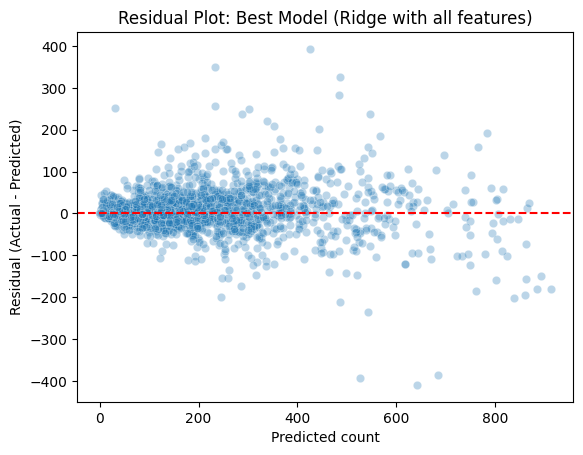

In [23]:
# Plot residuals for the best model

residuals = y_val - y_pred

sns.scatterplot(x=y_pred, y=residuals, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted count")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot: Best Model (Ridge with all features)")
plt.show()

In [24]:
# ============================================================
#  RETRAIN BEST RIDGE MODEL ON FULL TRAINING DATA
# ==========================================================

y_log = np.log1p(y_f)

best_ridge = Ridge(alpha=10)
best_ridge.fit(X_f, y_log)

# ============================================================
# PREDICT TEST DATA
# ============================================================
pred_log = best_ridge.predict(X_t)
pred = np.maximum(np.expm1(pred_log), 0)

# Submission
submission = pd.DataFrame({
    "datetime": bikes_test_df["datetime"],
    "count": pred
})

submission.to_csv("submission.csv", index=False)

print("\nSubmission saved!")
print(submission.head())


Submission saved!
             datetime       count
0 2012-06-05 05:00:00   25.802586
1 2011-03-19 19:00:00  110.150092
2 2012-04-02 06:00:00  109.347344
3 2012-07-13 20:00:00  371.568010
4 2011-11-09 19:00:00  281.696838


Explain why the winning model performs better
----------------------------------------------------------
The Ridge (full features) model wins because it uses a rich, problem-specific feature set that captures the key hour–condition patterns in bike demand, combined with L2 regularization (alpha=10) that keeps the model stable and generalizable, yielding much lower RMSLE than simpler or mis-regularized alternatives.

1. Linear Regression – RMSLE ≈ 0.905

The gap between linear and ridge regression despite using the same encodings and nonlinear features comes almost entirely from regularization and numerical stability.
If you used only a small, clean feature set, LinearRegression and Ridge might be close in performance. But with Hundreds/thousands of dummy + interaction columns. Many near-linear dependencies. the ordinary least squares solution becomes extremely sensitive. In that regime:LinearRegression effectively “uses up” its capacity fitting noise in the training set.

2. Ridge (full features) – RMSLE ≈ 0.38 (winner)

Ridge prevents any single feature or correlated group from dominating, forcing the model to rely on more robust, aggregate patterns (e.g., general hourly shape, broad weather effects).

This representation with Rich one-hot encodings of time (hour, day, month, etc.), targeted interaction features (especially hour × workingday/season/weather, etc.),squared terms for weather variables is well-matched to the data’s structure.  The model has enough capacity to fit different demand curves by hour and day type and Non-linear weather effects.

3. Ridge (degree-2 poly) – RMSLE ≈ 1.12

Applies a polynomial expansion (degree 2) to the base features.This creates many interaction and squared terms automatically, But they’re generic (all pairwise products), not tailored to the strongest signals. Combined with log-target and limited data, this can lead to over-parameterization in unhelpful directions.Even with Ridge (alpha=10), the feature space is noisy and not optimally aligned with the true patterns and worse than base linear.


Trade-offs between model simplicity and predictive power
-------------------------------------------------------------------
Simple models (few features, linear) are easier to interpret and explain and less prone to overfitting,often sufficient if performance is acceptable.

Complex models (many polynomial/interaction features, low regularization):can capture non-linear patterns and improve RMSLE and are harder to interpret.Risk overfitting, especially with limited data.
